# Data scarcity: 7 training users (minimal)

- **train:** 7 random users (never user 30, who holds the phone rotated), **test:** all the others; 5 random draws of the 7
- **pretraining:** the FIN imitates spectral entropy, autocorrelation peak and spectral peak on 30,000 *warped* copies of the 7 users' windows: sped up or slowed down, flipped, with noise.

- **pretrained, frozen:** only the head learns
- **random-init, trainable:** same architecture, random weights

In [1]:
import os
import sys
import warnings

os.environ["KERAS_BACKEND"] = "torch"
warnings.filterwarnings("ignore")
FIN = os.path.dirname(os.getcwd())
sys.path[:0] = [FIN, os.path.join(FIN, "FIN-classifiers"), os.path.join(FIN, "data-processing")]

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from keras import layers, ops
from sklearn.metrics import f1_score, recall_score

import config as cfg
import wisdm_windowing as ww
from augmentation import make, warped
from bilin_fin_temporal_plus_original import RhythmFIN, targets

SEEDS = (0, 1, 2, 3, 4)

## Data

In [2]:
windows, users, labels = ww.window_raw()
candidates = np.setdiff1d(np.unique(users), [30])
print(f"{len(windows)} windows, {len(np.unique(users))} users")

10367 windows, 36 users


In [3]:
N_SYNTH = 30000

## Model

In [4]:
class TestAccuracy(keras.callbacks.Callback):
    #test accuracy after each epoch for plots
    def __init__(self, x, y):
        super().__init__()
        self.x, self.y, self.curve = x, y, []

    def on_epoch_end(self, epoch, logs=None):
        rng = torch.random.get_rng_state()
        pred = self.model.predict(self.x, batch_size=1024, verbose=0).argmax(axis=1)
        torch.random.set_rng_state(rng)
        self.curve.append(float(np.mean(pred == self.y)))


class FINClassifier(keras.Model):
    def __init__(self, fin, **kw):
        super().__init__(**kw)
        self.fin = fin
        self.hidden = layers.Dense(cfg.HEAD_WIDTH, activation="relu")
        self.out = layers.Dense(cfg.N_CLASSES, activation="softmax")

    def call(self, x):
        h = ops.concatenate([self.fin.embed(x[:, i, :]) for i in range(len(cfg.AXES))], axis=1)
        return self.out(self.hidden(h))


def pretrain(axes, seed):
    keras.utils.set_random_seed(seed)
    fin = RhythmFIN()
    y = targets(axes)
    fin.compile(optimizer=keras.optimizers.Adam(cfg.FIN_LR), loss="mse")
    fin.fit(axes, ((y - y.mean(0)) / y.std(0)).astype(np.float32),
            epochs=cfg.FIN_EPOCHS, batch_size=cfg.BATCH_SIZE, verbose=0)
    return fin.get_weights()


def classify(tr, te, seed, weights, trainable):
    keras.utils.set_random_seed(seed)
    fin = RhythmFIN()
    if weights is not None:
        fin(np.zeros((1, cfg.SEGMENT), np.float32))
        fin.set_weights(weights)
    fin.trainable = trainable
    keras.utils.set_random_seed(seed)
    model = FINClassifier(fin)
    track = TestAccuracy(windows[te], labels[te])
    model.compile(optimizer=keras.optimizers.Adam(cfg.HEAD_LR), loss="sparse_categorical_crossentropy")
    model.fit(windows[tr], labels[tr], epochs=cfg.HEAD_EPOCHS, batch_size=cfg.BATCH_SIZE,
              verbose=0, callbacks=[track])
    pred = model.predict(windows[te], batch_size=1024, verbose=0).argmax(axis=1)
    return pred, track.curve


## Experiment

In [5]:
MODELS = {"pretrained, frozen": (True, False),
          "random-init, trainable": (False, True)}
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834"]))


def experiment(n_train):
    rows, curves = [], {m: [] for m in MODELS}
    for seed in SEEDS:
        picked = np.random.default_rng(seed).choice(candidates, n_train, replace=False)
        tr = np.isin(users, picked)
        te = ~tr
        weights = pretrain(make(N_SYNTH, seed, windows[tr].reshape(-1, cfg.SEGMENT)), seed)
        for model, (pretrained, trainable) in MODELS.items():
            pred, curve = classify(tr, te, seed, weights if pretrained else None, trainable)
            curves[model].append(curve)
            recall = recall_score(labels[te], pred, labels=range(cfg.N_CLASSES), average=None, zero_division=0)
            rows.append({"seed": seed, "train users": sorted(picked.tolist()), "model": model,
                         "accuracy": np.mean(pred == labels[te]),
                         "macro F1": f1_score(labels[te], pred, average="macro"),
                         **dict(zip(cfg.ACTIVITIES, recall))})
        print(f"seed {seed}: users {sorted(picked.tolist())} done")
    return pd.DataFrame(rows), curves


def summary(results):
    acc = results.pivot(index="seed", columns="model", values="accuracy")
    diff = pd.DataFrame({m + " - random": acc[m] - acc["random-init, trainable"] for m in list(MODELS)[:-1]})
    table = results.groupby("model")[["accuracy", "macro F1"]].agg(["mean", "std"]).loc[list(MODELS)]
    recall = results.groupby("model")[list(cfg.ACTIVITIES)].mean().loc[list(MODELS)]
    return table.round(4), diff.round(4), recall.round(3)


def plot(curves, n_train):
    epochs = np.arange(1, cfg.HEAD_EPOCHS + 1)
    fig, ax = plt.subplots(figsize=(7, 4))
    for model, color in COLORS.items():
        mean = np.mean(curves[model], axis=0)
        ax.plot(epochs, mean, color=color, linewidth=1.8, label=model)
        ax.annotate(f"{mean[-1]:.3f}", (epochs[-1], mean[-1]), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=9)
    ax.set_xlabel("epoch")
    ax.set_ylabel(f"test accuracy, {36 - n_train} unseen users")
    ax.set_xlim(1, cfg.HEAD_EPOCHS + 4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.6)
    ax.legend(frameon=False, loc="lower right")
    ax.set_title(f"FIN only, {n_train} training users, mean of {len(SEEDS)} draws", fontsize=10, loc="left")
    plt.tight_layout()
    plt.show()

In [6]:
results7, curves7 = experiment(7)

seed 0: users [2, 3, 9, 11, 16, 20, 25] done
seed 1: users [2, 5, 14, 16, 24, 29, 32] done
seed 2: users [4, 8, 10, 14, 16, 25, 28] done
seed 3: users [3, 6, 8, 24, 28, 32, 34] done
seed 4: users [17, 22, 28, 29, 33, 35, 36] done


In [7]:
table, diff, recall = summary(results7)
display(table, diff, recall)

accuracy         macro F1        
                           mean     std     mean     std
model                                                   
pretrained, frozen       0.8183  0.0400   0.7086  0.0431
random-init, trainable   0.8023  0.0398   0.6859  0.0442

,"pretrained, frozen - random"
seed,
0,0.0472
1,-0.0004
2,0.0170
3,0.0138
4,0.0022


,Jogging,Walking,Upstairs,Downstairs,Sitting,Standing
model,,,,,,
"pretrained, frozen",0.872,0.915,0.528,0.654,0.687,0.675
"random-init, trainable",0.885,0.866,0.525,0.659,0.726,0.608


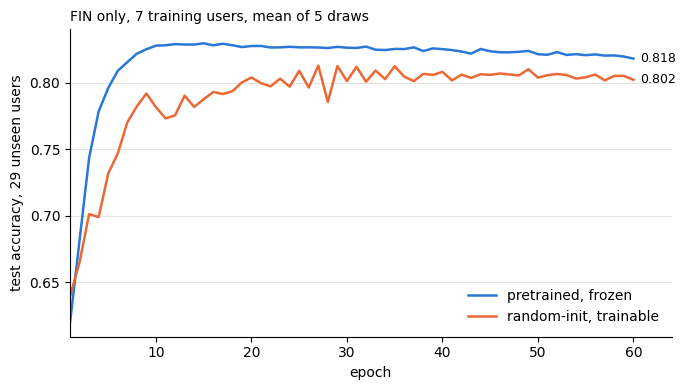

In [8]:
plot(curves7, 7)